In [ ]:
# numpy va en el setup para que las funciones (@app.function) lo puedan usar
import numpy as np

In [ ]:
import marimo as mo
import matplotlib.pyplot as plt

# Actividad 1 · Entrenamiento paso a paso de una neurona artificial

**Deep Learning para Computer Vision**

**Nombre:** Carlos Pulido Rosas

## Objetivo
Implementar y explicar el entrenamiento de una neurona para regresión con
NumPy, desde una predicción inicial hasta la actualización de sus parámetros.
Al finalizar, deberás relacionar las ecuaciones, las dimensiones de los
arreglos y el comportamiento de la pérdida durante el aprendizaje.

Usaremos una activación identidad: este modelo corresponde a una regresión
lineal. En clase lo abordamos como una primera aproximación al perceptrón.

## Instrucciones y entrega
- Completa las celdas con `TODO` y las respuestas marcadas con **Tu respuesta**.
- Implementa el modelo con NumPy. No utilices modelos de scikit-learn,
  TensorFlow, PyTorch ni herramientas de diferenciación automática.
- En cada paso incluye explicación, ecuación, código e interpretación.
- Conserva la convención de ejemplos en las **columnas** de `X`.
- Entrega este archivo `.py` de marimo con tus respuestas, código y gráficas.
  Debe ejecutarse completo sin errores y permitir reproducir los resultados.
- Los bloques incompletos devuelven `None` para que puedas abrir la plantilla.
  Sustitúyelos por tu implementación; no dejes resultados escritos a mano
  como reemplazo del código.

Esta actividad estudia la mecánica del entrenamiento. Los datos de trabajo
se usan para entrenar; no se evaluará generalización a datos nuevos.

## Perceptrón (regresión)

Como vimos en clase, la neurona recibe las entradas, las multiplica por sus
pesos, les suma el sesgo y el resultado pasa por una función de activación.
En este caso la activación es la identidad, así que la salida es
directamente la combinación lineal.

![Perceptron](https://raw.githubusercontent.com/IvTole/Topicos_Selectos_II_CUCEA/main/01_perceptron/images/perceptron.png)

Los pasos que vamos a seguir son los mismos de la clase:

1. Definir las dimensiones del perceptrón.
2. Inicializar pesos $W$ y sesgo $b$.
3. Propagación hacia adelante (predicción).
4. Calcular el error con la función de pérdida.
5. Calcular el gradiente (backpropagation).
6. Actualizar $W$ y $b$ con el descenso del gradiente.
7. Repetir 3 a 6 en un ciclo de entrenamiento.

## 1. Problema y datos

Predeciremos un **puntaje sintético de rendimiento** a partir de dos
características numéricas ya preparadas. Estos datos son didácticos y no
representan mediciones reales. No requieren limpieza ni estandarización.

1. Identifica las entradas y la salida del modelo.
2. ¿Por qué este problema es de regresión?
3. ¿Qué significa un ejemplo de entrenamiento en esta tabla?

**Respuesta:**

1. Las entradas son las dos características (las dos filas de `X_datos`,
   que llamo $x_1$ y $x_2$) y la salida es el puntaje (`y_datos`).
2. Es de regresión porque lo que queremos predecir es un número continuo,
   el puntaje puede ser -0.7, 1.3, 2.9, etc. No estamos clasificando en
   categorías.
3. Cada ejemplo es un renglón de la tabla: un par de valores $(x_1, x_2)$ con
   su puntaje. Dentro de `X` cada ejemplo es una **columna**. Tenemos 8
   ejemplos, o sea $m = 8$.

In [ ]:
X_datos = np.array([
    [-1.0, -0.5, 0.0, 0.5, 1.0, -1.0, 0.0, 1.0],
    [0.0, 1.0, -1.0, 0.5, -0.5, -1.0, 1.0, 1.0],
], dtype=float)
y_datos = np.array([
    [-0.7, -0.9, 1.3, 1.0, 2.9, 0.6, -0.4, 1.2]
], dtype=float)

In [ ]:
mo.ui.table([
    {"Ejemplo": i + 1, "Característica 1": float(X_datos[0, i]),
     "Característica 2": float(X_datos[1, i]), "Puntaje": float(y_datos[0, i])}
    for i in range(X_datos.shape[1])
])

[{'Ejemplo': 1, 'Característica 1': -1.0, 'Característica 2': 0.0, 'Puntaje': -0.7}, {'Ejemplo': 2, 'Característica 1': -0.5, 'Característica 2': 1.0, 'Puntaje': -0.9}, {'Ejemplo': 3, 'Característica 1': 0.0, 'Característica 2': -1.0, 'Puntaje': 1.3}, {'Ejemplo': 4, 'Característica 1': 0.5, 'Característica 2': 0.5, 'Puntaje': 1.0}, {'Ejemplo': 5, 'Característica 1': 1.0, 'Característica 2': -0.5, 'Puntaje': 2.9}, {'Ejemplo': 6, 'Característica 1': -1.0, 'Característica 2': -1.0, 'Puntaje': 0.6}, {'Ejemplo': 7, 'Característica 1': 0.0, 'Característica 2': 1.0, 'Puntaje': -0.4}, {'Ejemplo': 8, 'Característica 1': 1.0, 'Característica 2': 1.0, 'Puntaje': 1.2}]

In [ ]:
print(f"X_datos (shape): {X_datos.shape}")
print(f"y_datos (shape): {y_datos.shape}")

X_datos (shape): (2, 8)
y_datos (shape): (1, 8)


## 2. Dimensiones e inicialización

Usaremos $m$ ejemplos, $n_x$ características y una salida:

| Arreglo | Forma |
|---|---|
| $X$ | $(n_x,m)$ |
| $y$ | $(1,m)$ |
| $W$ | $(1,n_x)$ |
| $b$ | $(1,1)$ |
| $\hat y$ | $(1,m)$ |

Completa `layer_sizes` e `initialize_parameters`. Inicializa pesos pequeños
con `np.random.default_rng(seed)` y el sesgo en cero. Para esta neurona,
inicializar en cero también sería posible; usaremos una semilla para
comparar experimentos de forma reproducible.

**Tu respuesta:**

Con nuestros datos $n_x = 2$, $m = 8$ y $n_y = 1$, entonces $X$ es $(2, 8)$,
$y$ es $(1, 8)$, $W$ es $(1, 2)$, $b$ es $(1, 1)$ y $\hat y$ es $(1, 8)$.

El producto $WX$ se puede hacer porque $W$ tiene 2 columnas y $X$ tiene 2
filas: $(1, 2)\cdot(2, 8)$ da $(1, 8)$, una predicción para cada ejemplo.
Luego $b$ es de $(1, 1)$ y NumPy lo repite en las 8 columnas
(*broadcasting*), así que a todas las predicciones se les suma el mismo
sesgo.

La semilla fija los números aleatorios. Si uso la misma semilla, los pesos
iniciales salen iguales cada vez que corro el notebook, y así puedo comparar
experimentos (como las tasas de aprendizaje de la sección 8) empezando
desde el mismo punto.

### Paso 1
Definimos las dimensiones del perceptrón a partir de las formas de $X$ y $y$.

In [ ]:
def layer_sizes(X, y):
    """
    Argumentos:
    X -- datos de entrada con dimensiones (tamaño de entrada, número de ejemplos)
    y -- target con dimensiones (tamaño de salida, número de ejemplos)

    Retorna (tupla):
    n_x -- tamaño de la capa de entrada
    n_y -- tamaño de la capa de salida
    """
    n_x = X.shape[0]
    n_y = y.shape[0]
    return n_x, n_y

In [ ]:
(n_x, n_y) = layer_sizes(X_datos, y_datos)
print(f"Tamaño de la capa de entrada: {n_x}")
print(f"Tamaño de la capa de salida: {n_y}")

Tamaño de la capa de entrada: 2
Tamaño de la capa de salida: 1


Salen 2 entradas y 1 salida, que es lo que esperaba: dos características y un puntaje.

### Paso 2
Inicializamos los pesos $W$ con valores pequeños aleatorios (usando la
semilla) y el sesgo $b$ en cero.

In [ ]:
def initialize_parameters(n_x, n_y, seed=42):
    """
    Argumentos:
    n_x, n_y -- tamaños de entrada y salida
    seed -- semilla para que los resultados se puedan repetir

    Retorna:
    parameters (diccionario) -- pesos W de forma (n_y, n_x) y sesgo b de forma (n_y, 1)
    """
    rng = np.random.default_rng(seed)
    # pesos pequeños aleatorios
    W = rng.normal(0.0, 0.01, size=(n_y, n_x))
    # sesgo en cero
    b = np.zeros((n_y, 1))
    parameters = {
        "W": W,
        "b": b
    }
    return parameters

In [ ]:
parametros_iniciales = initialize_parameters(n_x, n_y, seed=42)
print("W:", parametros_iniciales["W"], "->", parametros_iniciales["W"].shape)
print("b:", parametros_iniciales["b"], "->", parametros_iniciales["b"].shape)

W: [[ 0.00304717 -0.01039984]] -> (1, 2)
b: [[0.]] -> (1, 1)


Los pesos salen muy chiquitos, del orden de 0.01, y el sesgo en 0. Las
formas son $(1, 2)$ y $(1, 1)$, igual que en la tabla. O sea, la neurona
arranca prácticamente sin "saber" nada.

## 3. Propagación hacia adelante

$$Z=WX+b,\qquad \hat y=Z$$

Implementa `forward_propagation`. Recibe los datos y un diccionario de
parámetros; devuelve un arreglo con todas las predicciones.

**Tu respuesta:**

Los pesos dicen qué tanto influye cada característica en la predicción. Si
$w_1$ es positivo, cuando $x_1$ sube el puntaje sube, y si es negativo,
baja. El sesgo es lo que predice el modelo cuando las dos entradas valen
cero; sube o baja todo el plano sin cambiar su inclinación.

Usamos la identidad porque queremos predecir un número real sin límite.
Una sigmoide, por ejemplo, dejaría la salida entre 0 y 1, y aquí hay
puntajes negativos y mayores que 1. Con la identidad la neurona es una
regresión lineal.

### Paso 3
Forward propagation (inferencia).

In [ ]:
def forward_propagation(X, parameters):
    """
    Argumentos:
    X -- datos de entrada (n_x, m)
    parameters -- diccionario con W y b

    Retorna:
    y_hat -- predicciones (1, m)
    """
    # Extraigo parámetros
    W = parameters["W"]
    b = parameters["b"]
    # propagación hacia adelante
    Z = W @ X + b
    # predicción (activación identidad)
    y_hat = Z
    return y_hat

In [ ]:
y_hat_inicial = forward_propagation(X_datos, parametros_iniciales)
print(y_hat_inicial.round(4), "->", y_hat_inicial.shape)

[[-0.003  -0.0119  0.0104 -0.0037  0.0082  0.0074 -0.0104 -0.0074]] -> (1, 8)


Como los pesos empiezan casi en cero, todas las predicciones iniciales
salen muy cerca de cero.

## 4. Función de pérdida

$$J(W,b)=\frac{1}{2m}\sum_{i=1}^{m}(\hat y^{(i)}-y^{(i)})^2$$

Implementa `compute_cost`: debe devolver un escalar. Utiliza `np.sum`;
si aparecen valores no finitos, investiga su causa.

**Tu respuesta:**

Lo elevamos al cuadrado para que los errores positivos y negativos no se
cancelen al sumarlos. Además así los errores grandes pesan mucho más que
los chicos, y la función queda suave, se puede derivar en todos lados, lo
que nos sirve para el descenso del gradiente.

El $\frac{1}{2}$ está ahí por comodidad. Cuando derivamos $(\hat y - y)^2$ sale
un 2 que se cancela con el $\frac{1}{2}$, y el gradiente queda más limpio. No
cambia en dónde está el mínimo.

No, una pérdida de cero no asegura que el modelo funcione bien con datos
nuevos. Solo dice que le atinó a los datos de entrenamiento, y pudo haberse
"aprendido" también el ruido (sobreajuste). Para saberlo habría que probarlo
con datos que no vio al entrenar.

### Paso 4
Calcular el error (función de pérdida).

In [ ]:
def compute_cost(y_hat, y):
    """
    Argumentos:
    y_hat -- predicción de la neurona (1, m)
    y -- target (1, m)

    Retorna:
    cost -- pérdida (escalar)
    """
    # número de ejemplos
    m = y.shape[1]
    # cálculo del error
    cost = np.sum((y_hat - y) ** 2) / (2 * m)
    return float(cost)

In [ ]:
print(f"Pérdida inicial: {compute_cost(y_hat_inicial, y_datos):.6f}")

Pérdida inicial: 0.891738


Este 0.89 es el error de arranque. Tiene sentido: como la neurona predice
casi 0 para todos, la pérdida queda muy cerca de $\frac{1}{2m}\sum y^2$, que
con estos datos da 0.8975. Este es el número que el entrenamiento tiene que
bajar.

## 5. Gradientes y actualización

Con pesos organizados como **fila**, las ecuaciones son:

$$dZ=\hat y-y,\qquad dW=\frac{1}{m}dZ X^T,
\qquad db=\frac{1}{m}\sum_{i=1}^{m}dZ^{(i)}$$

$$W_{\mathrm{nuevo}}=W-\alpha dW,\qquad
b_{\mathrm{nuevo}}=b-\alpha db$$

Implementa las dos funciones. Conserva las formas de `dW` y `db`;
`np.sum(..., axis=1, keepdims=True)` puede ayudarte con el sesgo.
La actualización debe devolver un diccionario nuevo sin modificar
los arreglos originales en el lugar.

**Tu respuesta:**

Para un ejemplo $i$ la predicción es
$\hat y^{(i)} = W_1 x_1^{(i)} + W_2 x_2^{(i)} + b$. Si derivo respecto a un
peso me queda $\partial \hat y^{(i)}/\partial W_j = x_j^{(i)}$, y respecto al
sesgo $\partial \hat y^{(i)}/\partial b = 1$. Con la regla de la cadena:

$$\frac{\partial J}{\partial W_j}
= \frac{1}{2m}\sum_{i=1}^{m} 2(\hat y^{(i)}-y^{(i)})\,x_j^{(i)}
= \frac{1}{m}\sum_{i=1}^{m} (\hat y^{(i)}-y^{(i)})\,x_j^{(i)}$$

$$\frac{\partial J}{\partial b}
= \frac{1}{2m}\sum_{i=1}^{m} 2(\hat y^{(i)}-y^{(i)})
= \frac{1}{m}\sum_{i=1}^{m} (\hat y^{(i)}-y^{(i)})$$

Si llamo $dZ = \hat y - y$, que es de $(1, m)$, esa suma para los dos pesos
al mismo tiempo es el producto $dZ\,X^T$: $(1, m)(m, 2) = (1, 2)$, la misma
forma que $W$. Por eso $dW = \frac{1}{m} dZ X^T$, y $db$ es el promedio de
$dZ$.

Restamos porque el gradiente apunta hacia donde la pérdida **sube** más
rápido; si vamos en sentido contrario, baja. La tasa de aprendizaje
$\alpha$ es el tamaño del paso: muy chica y el modelo aprende lento, muy
grande y se puede pasar del mínimo.

### Paso 5
Backpropagation: calculamos el gradiente de la pérdida.

In [ ]:
def back_propagation(y_hat, y, X):
    """
    Argumentos:
    y_hat -- predicción (1, m)
    y -- observaciones reales (1, m)
    X -- matriz de datos (n_x, m)

    Retorna:
    grads (diccionario) -- gradiente de la pérdida respecto a W (dW) y b (db)
    """
    # m, número total de ejemplos
    m = X.shape[1]
    # derivadas parciales
    dZ = y_hat - y
    dW = (1 / m) * (dZ @ X.T)
    db = (1 / m) * np.sum(dZ, axis=1, keepdims=True)
    grads = {
        "dW": dW,
        "db": db
    }
    return grads

### Paso 6
Actualizamos $W$ y $b$ con el descenso del gradiente,
$W = W - \alpha\, dW$ y $b = b - \alpha\, db$.

In [ ]:
def update_parameters(parameters, grads, learning_rate):
    """
    Argumentos:
    parameters -- diccionario de parámetros (W, b)
    grads -- diccionario de gradientes (dW, db)
    learning_rate -- tasa de aprendizaje alpha

    Retorna:
    parámetros actualizados (diccionario nuevo, no modifica el original)
    """
    # Extraigo parámetros y gradientes
    W = parameters["W"]
    b = parameters["b"]
    dW = grads["dW"]
    db = grads["db"]
    # descenso del gradiente (se crean arreglos nuevos)
    W_nuevo = W - learning_rate * dW
    b_nuevo = b - learning_rate * db
    return {"W": W_nuevo, "b": b_nuevo}

In [ ]:
grads_prueba = back_propagation(y_hat_inicial, y_datos, X_datos)
parametros_prueba = update_parameters(parametros_iniciales, grads_prueba, learning_rate=0.1)
print("dW:", grads_prueba["dW"].round(4), "->", grads_prueba["dW"].shape)
print("db:", grads_prueba["db"].round(4), "->", grads_prueba["db"].shape)
print("W después de un paso:", parametros_prueba["W"].round(4))
print("b después de un paso:", parametros_prueba["b"].round(4))

dW: [[-0.6437  0.3621]] -> (1, 2)
db: [[-0.6263]] -> (1, 1)
W después de un paso: [[ 0.0674 -0.0466]]
b después de un paso: [[0.0626]]


Los signos del gradiente ya dicen hacia dónde se van a mover los parámetros.
$dW_1$ sale negativo, entonces al restarlo $w_1$ **sube**; $dW_2$ sale
positivo, entonces $w_2$ **baja**; y $db$ es negativo, así que $b$ sube. Más
adelante se ve que el entrenamiento termina justo así: $w_1$ positivo, $w_2$
negativo y $b$ positivo. También se ve que con un solo paso de 0.1 los
cambios son chiquitos, por eso hacen falta muchas iteraciones.

## 6. Una iteración a mano y con NumPy

Utiliza exclusivamente los siguientes dos ejemplos y parámetros:

$$X_{\mathrm{manual}}=\begin{bmatrix}1&2\\0&1\end{bmatrix},
\quad y_{\mathrm{manual}}=\begin{bmatrix}2&3\end{bmatrix}$$
$$W_0=\begin{bmatrix}0&0\end{bmatrix},\quad b_0=0,\quad\alpha=0.1$$

**Ejercicio:**, desarrolla a mano las predicciones iniciales,
la pérdida, `dZ`, `dW`, `db`, los parámetros actualizados y la pérdida
después de la actualización. Escribe las operaciones, no solo el resultado.

**Tu desarrollo:**

Aquí $m = 2$. El ejemplo 1 es $x^{(1)} = (1, 0)$ con $y^{(1)} = 2$, y el
ejemplo 2 es $x^{(2)} = (2, 1)$ con $y^{(2)} = 3$.

**Predicciones iniciales.** Con $W_0 = [0\ 0]$ y $b_0 = 0$:

$$\hat y = W_0 X + b_0 = [0(1) + 0(0),\ \ 0(2) + 0(1)] + 0 = [0\ \ 0]$$

**Pérdida inicial.**

$$J_0 = \frac{1}{2(2)}\left[(0-2)^2 + (0-3)^2\right] = \frac{4 + 9}{4} = 3.25$$

**dZ, dW y db.**

$$dZ = \hat y - y = [0-2,\ \ 0-3] = [-2\ \ -3]$$

$$dZ\,X^T = [-2\ \ -3]\begin{bmatrix}1&0\\2&1\end{bmatrix}
= [(-2)(1) + (-3)(2),\ \ (-2)(0) + (-3)(1)] = [-8\ \ -3]$$

$$dW = \tfrac{1}{2}[-8\ \ -3] = [-4\ \ -1.5]$$

$$db = \tfrac{1}{2}\left[(-2) + (-3)\right] = -2.5$$

**Actualización.**

$$W_1 = [0\ \ 0] - 0.1[-4\ \ -1.5] = [0.4\ \ 0.15]$$

$$b_1 = 0 - 0.1(-2.5) = 0.25$$

**Nuevas predicciones y pérdida.**

$$\hat y^{(1)} = 0.4(1) + 0.15(0) + 0.25 = 0.65$$

$$\hat y^{(2)} = 0.4(2) + 0.15(1) + 0.25 = 1.20$$

$$J_1 = \frac{1}{4}\left[(0.65-2)^2 + (1.20-3)^2\right]
= \frac{1.8225 + 3.24}{4} = \frac{5.0625}{4} = 1.265625$$

Después, completa la celda para repetir el cálculo usando tus funciones.
Muestra los valores y comprueba que coinciden con tu
desarrollo manual. Explica cualquier diferencia por redondeo.

**Tu interpretación:**

Sí, la pérdida bajó de 3.25 a 1.265625 con un solo paso, más o menos a la
mitad. Las dos predicciones subieron hacia su valor real (de 0 a 0.65 y de
0 a 1.20), aunque todavía les falta para llegar a 2 y 3. Los resultados de
NumPy salen igual que a mano. Si hubiera diferencias serían del orden de
$10^{-16}$, por cómo la computadora guarda números como 0.1, pero en este
caso los `assert` pasan sin problema.

In [ ]:
X_manual = np.array([[1.0, 2.0], [0.0, 1.0]])
y_manual = np.array([[2.0, 3.0]])
parametros_manual = {"W": np.zeros((1, 2)), "b": np.zeros((1, 1))}
alpha_manual = 0.1

# antes de actualizar
y_hat_0 = forward_propagation(X_manual, parametros_manual)
J_0 = compute_cost(y_hat_0, y_manual)
grads_manual = back_propagation(y_hat_0, y_manual, X_manual)
# actualización
parametros_1 = update_parameters(parametros_manual, grads_manual, alpha_manual)
# después de actualizar
y_hat_1 = forward_propagation(X_manual, parametros_1)
J_1 = compute_cost(y_hat_1, y_manual)

print("Predicciones iniciales:", y_hat_0)
print("Pérdida inicial:", J_0)
print("dZ:", y_hat_0 - y_manual)
print("dW:", grads_manual["dW"], "  db:", grads_manual["db"])
print("W1:", parametros_1["W"], "  b1:", parametros_1["b"])
print("Predicciones después:", y_hat_1)
print("Pérdida después:", J_1)

# reviso que coincida con lo que hice a mano
assert np.isclose(J_0, 3.25)
assert np.allclose(grads_manual["dW"], [[-4.0, -1.5]])
assert np.allclose(grads_manual["db"], [[-2.5]])
assert np.allclose(parametros_1["W"], [[0.4, 0.15]])
assert np.allclose(parametros_1["b"], [[0.25]])
assert np.allclose(y_hat_1, [[0.65, 1.20]])
assert np.isclose(J_1, 1.265625)
# y que no se modificaron los parámetros originales
assert np.all(parametros_manual["W"] == 0) and np.all(parametros_manual["b"] == 0)
print("Todo coincide con el cálculo a mano.")

Predicciones iniciales: [[0. 0.]]
Pérdida inicial: 3.25
dZ: [[-2. -3.]]
dW: [[-4.  -1.5]]   db: [[-2.5]]
W1: [[0.4  0.15]]   b1: [[0.25]]
Predicciones después: [[0.65 1.2 ]]
Pérdida después: 1.265625
Todo coincide con el cálculo a mano.


## 7. Ciclo de entrenamiento

Integra tus funciones en `train_model`:

1. Obtén las dimensiones usando los argumentos `X` e `y`.
2. Inicializa los parámetros una sola vez.
3. Guarda la pérdida inicial.
4. En cada iteración: predice, calcula gradientes, actualiza parámetros
   y guarda la pérdida **después** de actualizar.
5. Devuelve los parámetros finales y el historial de pérdidas.

El historial debe tener `iterations + 1` valores: el índice cero es
la pérdida antes de entrenar. Usa únicamente los datos recibidos por
la función, para que también funcione con el conjunto del cálculo manual.

Entrena con 200 iteraciones, tasa 0.1 y semilla 42. Muestra los parámetros,
las predicciones finales, las pérdidas inicial y final y una gráfica
de pérdida contra número de actualizaciones.

**Tu respuesta:**

En cada vuelta del ciclo se repiten los pasos 3 a 6: predecir con los
parámetros que hay en ese momento, calcular la pérdida y el gradiente, y
actualizar $W$ y $b$. Lo que se va conservando son los parámetros: cada
iteración arranca con los $W$ y $b$ que dejó la anterior, no se vuelven a
inicializar. Los datos son siempre los mismos.

Sí, cada iteración usa los 8 ejemplos, porque el gradiente es el promedio
sobre todo $X$. A esto se le llama descenso del gradiente por lote
completo (*batch*). Si en cada paso usáramos solo un ejemplo o un grupo de
ejemplos sería estocástico o por minilotes.

In [ ]:
def train_model(X, y, iterations=200, learning_rate=0.1, seed=42):
    """
    Argumentos:
    X, y -- datos de entrenamiento
    iterations -- número de actualizaciones
    learning_rate -- tasa de aprendizaje alpha
    seed -- semilla de la inicialización

    Retorna:
    parameters -- W y b finales
    cost_history -- pérdidas (iterations + 1 valores, el índice 0 es antes de entrenar)
    """
    # paso 1 - dimensiones
    n_x, n_y = layer_sizes(X, y)
    # paso 2 - inicializar (una sola vez)
    parameters = initialize_parameters(n_x, n_y, seed=seed)
    # pérdida antes de entrenar
    cost_history = [compute_cost(forward_propagation(X, parameters), y)]
    # ciclo de entrenamiento
    for i in range(iterations):
        # paso 3 - forward propagation
        y_hat = forward_propagation(X, parameters)
        # paso 5 - gradiente
        grads = back_propagation(y_hat, y, X)
        # paso 6 - actualizar W, b
        parameters = update_parameters(parameters, grads, learning_rate)
        # paso 4 - pérdida después de actualizar
        cost_history.append(compute_cost(forward_propagation(X, parameters), y))
    return parameters, np.array(cost_history)

In [ ]:
params_final, historial = train_model(X_datos, y_datos, iterations=200,
                                      learning_rate=0.1, seed=42)
y_hat_final = forward_propagation(X_datos, params_final)

print("W final:", params_final["W"].round(4))
print("b final:", params_final["b"].round(4))
print("Predicciones finales:", y_hat_final.round(3))
print("Valores reales:      ", y_datos)
print(f"Pérdida inicial: {historial[0]:.6f}")
print(f"Pérdida final:   {historial[-1]:.6f}")
print("Número de valores en el historial:", len(historial))

W final: [[ 1.4208 -0.9955]]
b final: [[0.7494]]
Predicciones finales: [[-0.671 -0.956  1.745  0.962  2.668  0.324 -0.246  1.175]]
Valores reales:       [[-0.7 -0.9  1.3  1.   2.9  0.6 -0.4  1.2]]
Pérdida inicial: 0.891738
Pérdida final:   0.022355
Número de valores en el historial: 201


In [ ]:
# comparo lo real contra lo que predecía antes y después de entrenar
_antes = forward_propagation(X_datos, parametros_iniciales)
mo.ui.table([
    {"Ejemplo": i + 1,
     "Real": float(y_datos[0, i]),
     "Predicción antes": round(float(_antes[0, i]), 3),
     "Predicción después": round(float(y_hat_final[0, i]), 3),
     "Error después": round(float(y_hat_final[0, i] - y_datos[0, i]), 3)}
    for i in range(y_datos.shape[1])
])

[{'Ejemplo': 1, 'Real': -0.7, 'Predicción antes': -0.003, 'Predicción después': -0.671, 'Error después': 0.029}, {'Ejemplo': 2, 'Real': -0.9, 'Predicción antes': -0.012, 'Predicción después': -0.956, 'Error después': -0.056}, {'Ejemplo': 3, 'Real': 1.3, 'Predicción antes': 0.01, 'Predicción después': 1.745, 'Error después': 0.445}, {'Ejemplo': 4, 'Real': 1.0, 'Predicción antes': -0.004, 'Predicción después': 0.962, 'Error después': -0.038}, {'Ejemplo': 5, 'Real': 2.9, 'Predicción antes': 0.008, 'Predicción después': 2.668, 'Error después': -0.232}, {'Ejemplo': 6, 'Real': 0.6, 'Predicción antes': 0.007, 'Predicción después': 0.324, 'Error después': -0.276}, {'Ejemplo': 7, 'Real': -0.4, 'Predicción antes': -0.01, 'Predicción después': -0.246, 'Error después': 0.154}, {'Ejemplo': 8, 'Real': 1.2, 'Predicción antes': -0.007, 'Predicción después': 1.175, 'Error después': -0.025}]

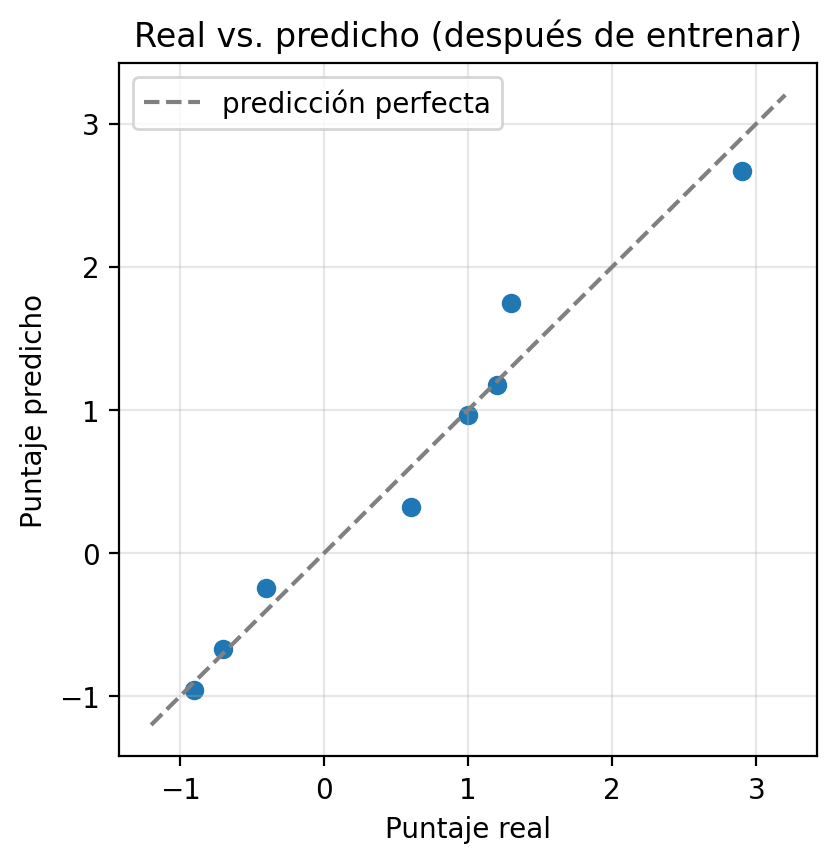

In [ ]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(y_datos.ravel(), y_hat_final.ravel())
plt.plot([-1.2, 3.2], [-1.2, 3.2], "--", color="gray", label="predicción perfecta")
plt.xlabel("Puntaje real")
plt.ylabel("Puntaje predicho")
plt.title("Real vs. predicho (después de entrenar)")
plt.legend()
plt.grid(alpha=0.3)
plt.gca()

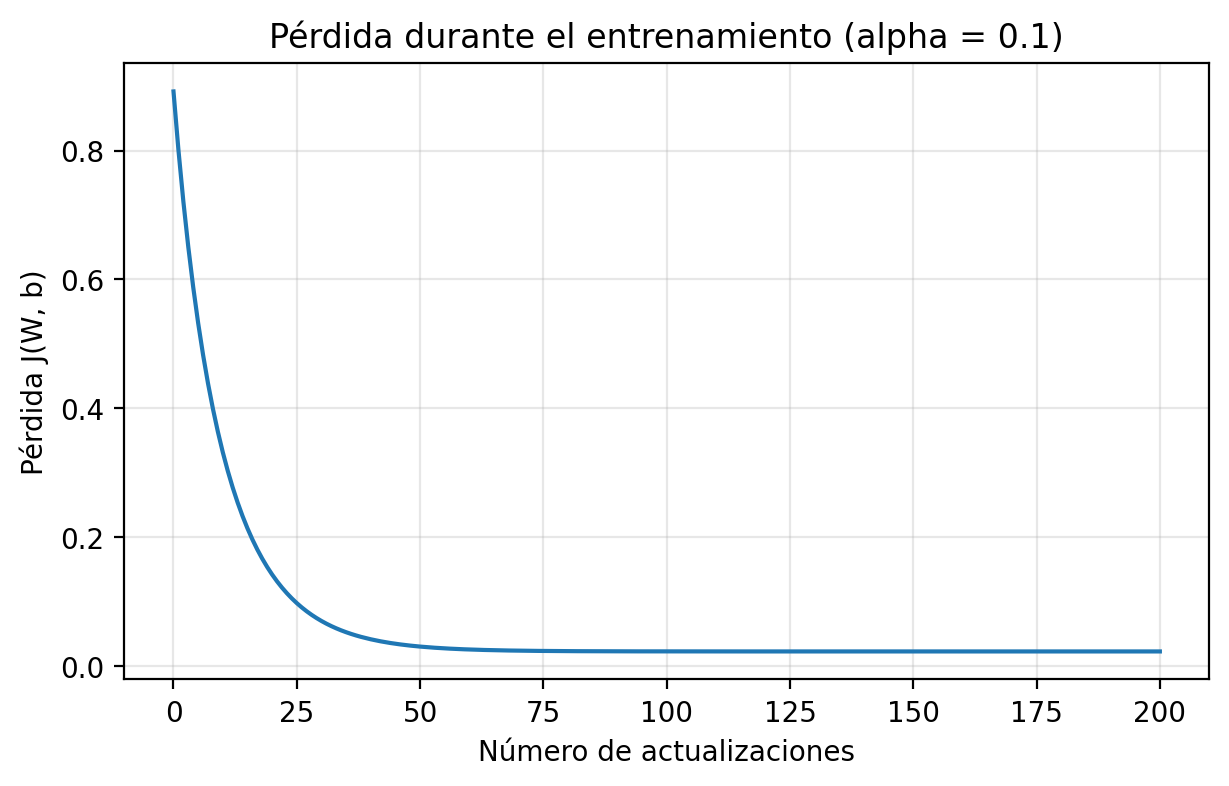

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(historial)), historial)
plt.xlabel("Número de actualizaciones")
plt.ylabel("Pérdida J(W, b)")
plt.title("Pérdida durante el entrenamiento (alpha = 0.1)")
plt.grid(alpha=0.3)
plt.gca()

In [ ]:
mo.md(rf"""
La pérdida baja de {historial[0]:.4f} a {historial[-1]:.4f}. Al principio cae
muy rápido, en unas 40 iteraciones ya bajó casi todo, y luego se va aplanando
porque cerca del mínimo el gradiente es chico y los pasos también. Los pesos
finales ($w_1 \approx$ {params_final["W"][0, 0]:.2f} y
$w_2 \approx$ {params_final["W"][0, 1]:.2f}) quieren decir que el puntaje
sube con la característica 1 y baja con la 2. La pérdida no llega a cero
porque los puntos no caen exactamente en un plano, así que siempre queda
algo de error que un modelo lineal no puede quitar.

En la tabla se ve mejor: antes de entrenar todas las predicciones eran casi
0, y después quedan cerca de los reales. Los que más fallan son el ejemplo 3
(predice 1.75 y el real es 1.3) y el 6 (0.32 contra 0.6), pero el resto
quedan a menos de 0.25. En la gráfica los puntos caen cerca de la línea
punteada, que sería acertarle exacto.
""")

La pérdida baja de 0.8917 a 0.0224. Al principio cae
muy rápido, en unas 40 iteraciones ya bajó casi todo, y luego se va aplanando
porque cerca del mínimo el gradiente es chico y los pasos también. Los pesos
finales ($w_1 \approx$ 1.42 y
$w_2 \approx$ -1.00) quieren decir que el puntaje
sube con la característica 1 y baja con la 2. La pérdida no llega a cero
porque los puntos no caen exactamente en un plano, así que siempre queda
algo de error que un modelo lineal no puede quitar.

En la tabla se ve mejor: antes de entrenar todas las predicciones eran casi
0, y después quedan cerca de los reales. Los que más fallan son el ejemplo 3
(predice 1.75 y el real es 1.3) y el 6 (0.32 contra 0.6), pero el resto
quedan a menos de 0.25. En la gráfica los puntos caen cerca de la línea
punteada, que sería acertarle exacto.

## 8. Experimento con la tasa de aprendizaje

Repite el entrenamiento con $\alpha\in\{0.01,0.1,3.0\}$.
Usa los mismos datos, **200 iteraciones y la misma semilla** en todos
los casos. Reinicia el entrenamiento del modelo para cada experimento.

- Grafica las tres curvas, con leyenda y ejes etiquetados. Puedes usar
  escala logarítmica o paneles separados si las magnitudes lo requieren.
- Construye una tabla con tasa, pérdida inicial, pérdida final y
  si observaste convergencia, oscilaciones o divergencia.
- Si aparecen valores no finitos, indícalos y explica lo ocurrido.

In [ ]:
tasas = [0.01, 0.1, 3.0]
historiales = {}
pesos_w1 = {}
for alpha in tasas:
    # cada llamada a train_model inicializa de nuevo con la misma semilla
    _, historiales[alpha] = train_model(X_datos, y_datos, iterations=200,
                                        learning_rate=alpha, seed=42)
    # para ver si oscila, repito el ciclo guardando w1 en cada paso
    _p = initialize_parameters(2, 1, seed=42)
    _w1 = [_p["W"][0, 0]]
    for _i in range(200):
        _g = back_propagation(forward_propagation(X_datos, _p), y_datos, X_datos)
        _p = update_parameters(_p, _g, alpha)
        _w1.append(_p["W"][0, 0])
    pesos_w1[alpha] = np.array(_w1)

In [ ]:
def cambios_direccion(w):
    # cuántas veces w1 pasa de subir a bajar (o al revés)
    pasos = np.sign(np.diff(w))
    return int(np.sum(pasos[1:] != pasos[:-1]))

def comportamiento(h, w):
    if not np.all(np.isfinite(h)):
        return "Divergencia (valores no finitos)"
    if h[-1] > h[0]:
        if cambios_direccion(w) > len(w) // 2:
            return "Oscila y diverge"
        return "Divergencia"
    if abs(h[-1] - h[-2]) < 1e-6:
        return "Convergencia"
    return "Converge lento (sigue bajando)"

mo.ui.table([
    {"Tasa": alpha,
     "Pérdida inicial": round(historiales[alpha][0], 6),
     "Pérdida final": f"{historiales[alpha][-1]:.6g}",
     "Valores finitos": bool(np.all(np.isfinite(historiales[alpha]))),
     "Cambios de dirección de w1": cambios_direccion(pesos_w1[alpha]),
     "Comportamiento": comportamiento(historiales[alpha], pesos_w1[alpha])}
    for alpha in tasas
])

[{'Tasa': 0.01, 'Pérdida inicial': np.float64(0.891738), 'Pérdida final': '0.146595', 'Valores finitos': True, 'Cambios de dirección de w1': 0, 'Comportamiento': 'Converge lento (sigue bajando)'}, {'Tasa': 0.1, 'Pérdida inicial': np.float64(0.891738), 'Pérdida final': '0.022355', 'Valores finitos': True, 'Cambios de dirección de w1': 0, 'Comportamiento': 'Convergencia'}, {'Tasa': 3.0, 'Pérdida inicial': np.float64(0.891738), 'Pérdida final': '1.22384e+132', 'Valores finitos': True, 'Cambios de dirección de w1': 199, 'Comportamiento': 'Oscila y diverge'}]

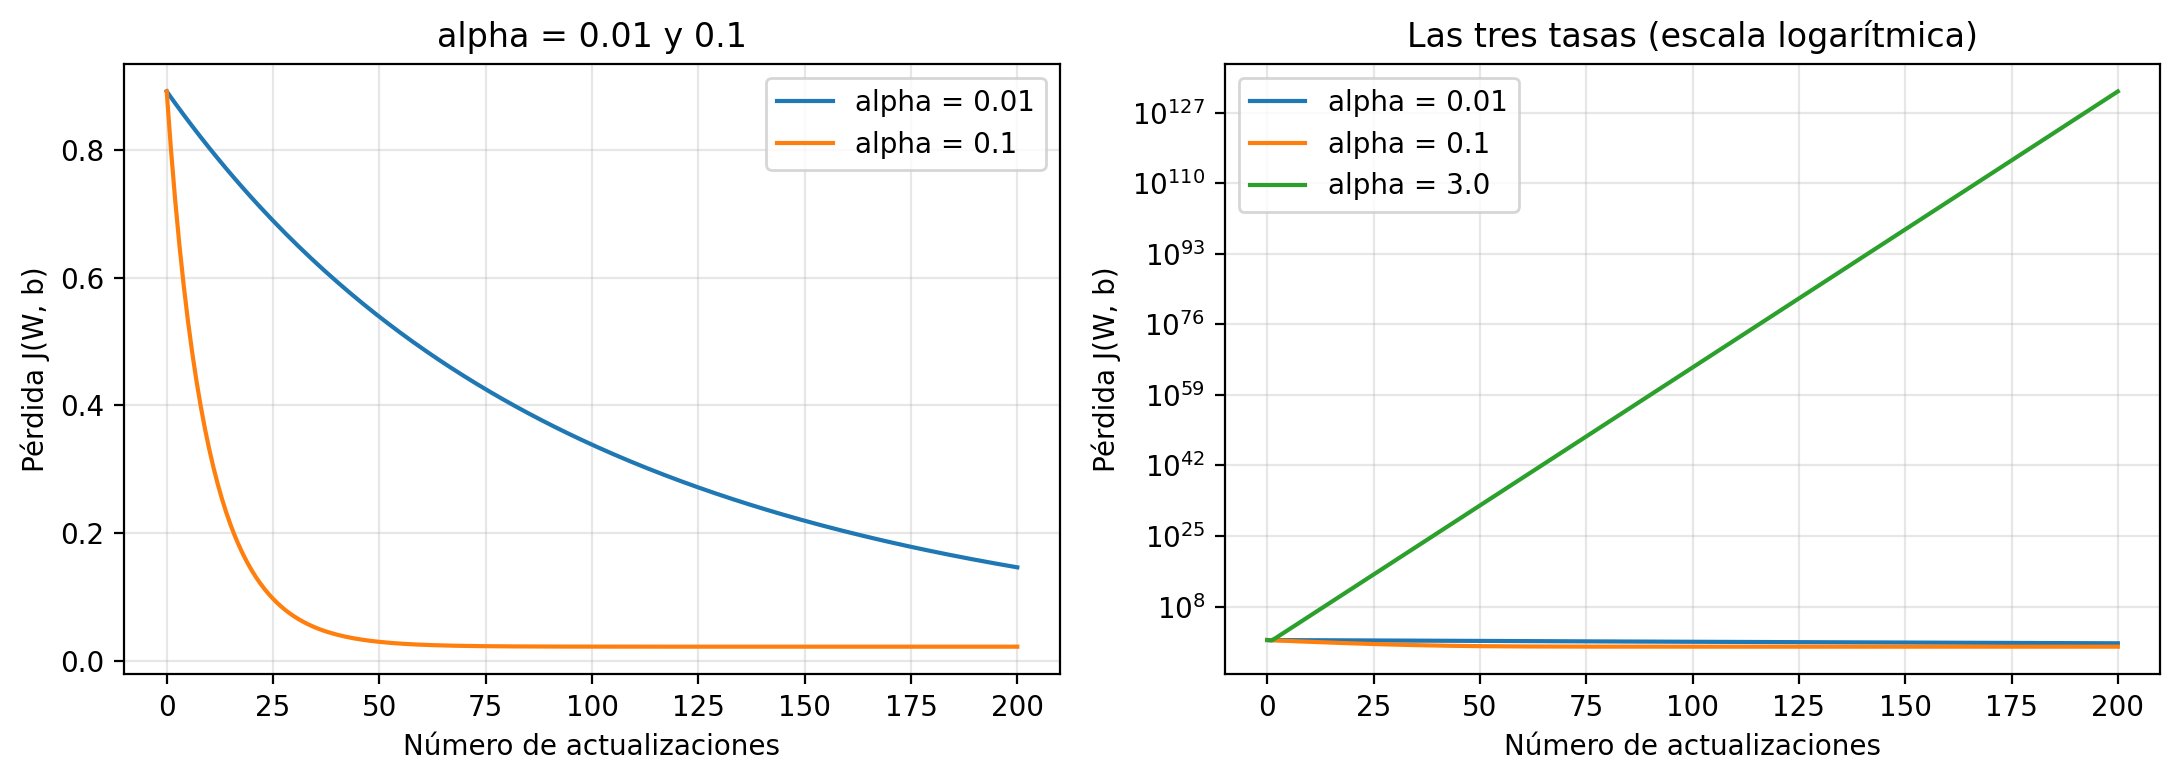

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# izquierda: las dos que convergen, escala normal
ax[0].plot(historiales[0.01], label="alpha = 0.01")
ax[0].plot(historiales[0.1], label="alpha = 0.1")
ax[0].set_title("alpha = 0.01 y 0.1")
ax[0].set_xlabel("Número de actualizaciones")
ax[0].set_ylabel("Pérdida J(W, b)")
ax[0].legend()
ax[0].grid(alpha=0.3)
# derecha: las tres en escala log, porque 3.0 crece muchísimo
for _a in [0.01, 0.1, 3.0]:
    ax[1].semilogy(historiales[_a], label=f"alpha = {_a}")
ax[1].set_title("Las tres tasas (escala logarítmica)")
ax[1].set_xlabel("Número de actualizaciones")
ax[1].set_ylabel("Pérdida J(W, b)")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
fig

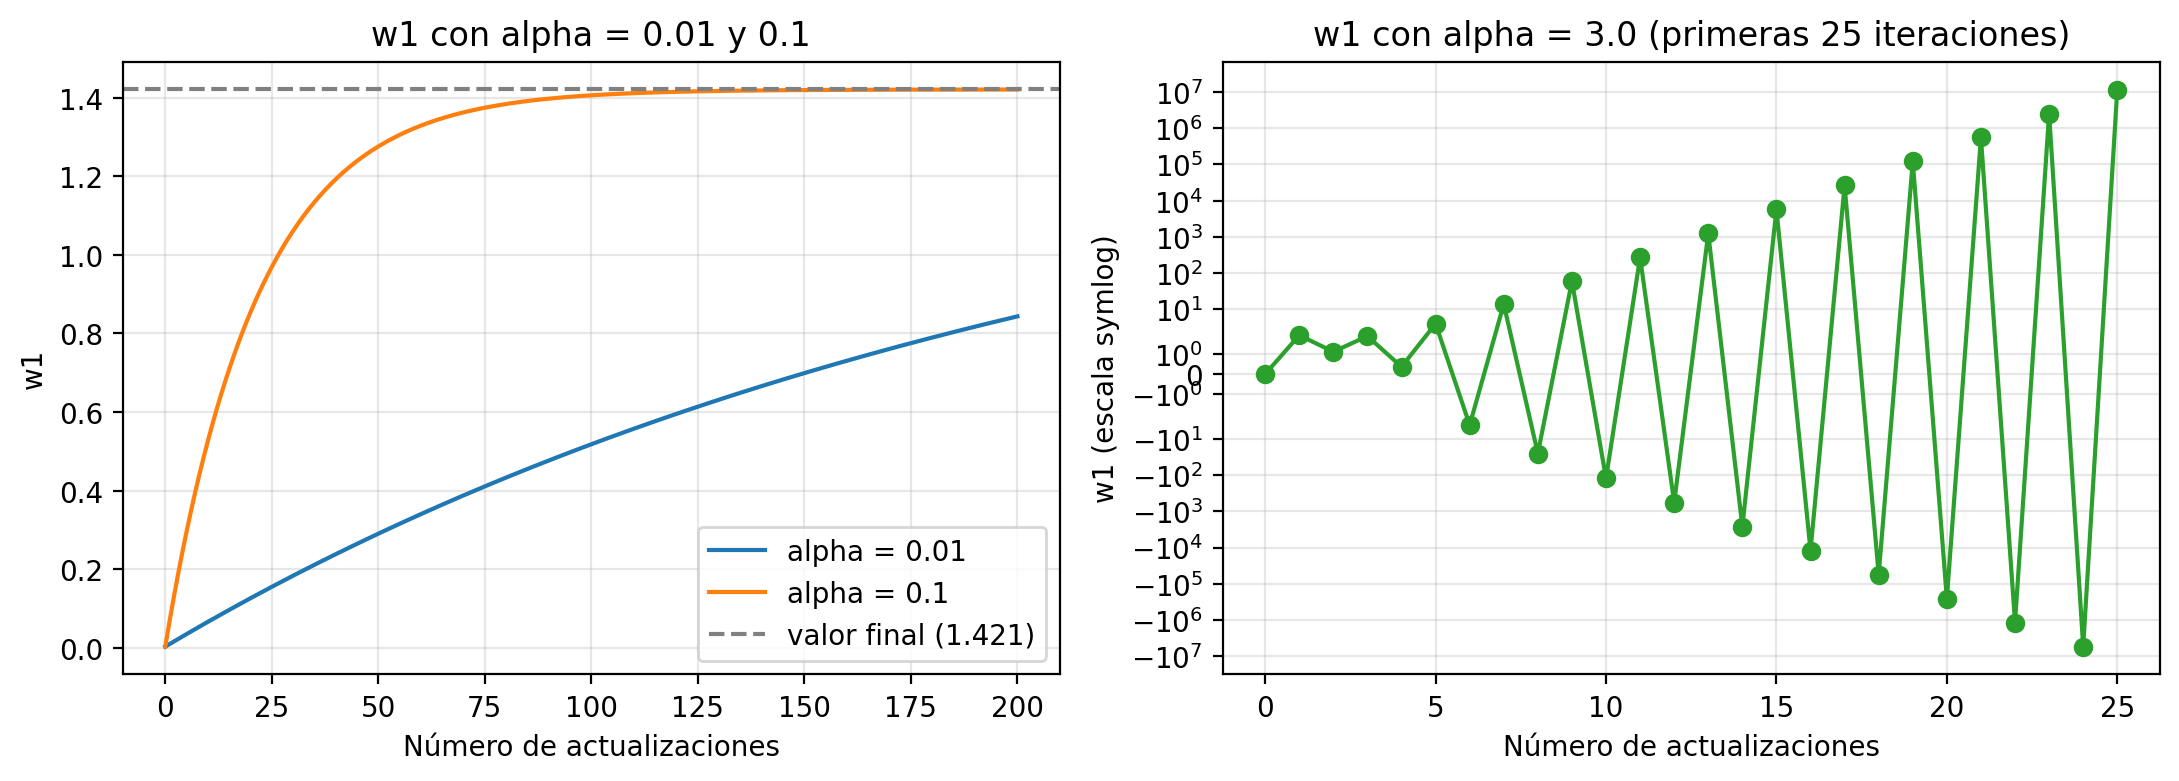

In [ ]:
fig_w, ax_w = plt.subplots(1, 2, figsize=(11, 4))
ax_w[0].plot(pesos_w1[0.01], label="alpha = 0.01")
ax_w[0].plot(pesos_w1[0.1], label="alpha = 0.1")
ax_w[0].axhline(1.421, ls="--", color="gray", label="valor final (1.421)")
ax_w[0].set_title("w1 con alpha = 0.01 y 0.1")
ax_w[0].set_xlabel("Número de actualizaciones")
ax_w[0].set_ylabel("w1")
ax_w[0].legend()
ax_w[0].grid(alpha=0.3)
# con 3.0 solo las primeras 25 para que se vea el zigzag
ax_w[1].plot(pesos_w1[3.0][:26], marker="o", color="tab:green")
ax_w[1].set_yscale("symlog")
ax_w[1].set_title("w1 con alpha = 3.0 (primeras 25 iteraciones)")
ax_w[1].set_xlabel("Número de actualizaciones")
ax_w[1].set_ylabel("w1 (escala symlog)")
ax_w[1].grid(alpha=0.3)
plt.tight_layout()
fig_w

Me dio curiosidad saber en qué punto deja de funcionar, así que probé
algunas tasas entre 0.1 y 3.0 con las mismas condiciones:

In [ ]:
tasas_extra = [0.5, 1.0, 1.5, 1.8, 1.9, 2.0, 2.5]
filas_extra = []
for _a in tasas_extra:
    _, _h = train_model(X_datos, y_datos, iterations=200, learning_rate=_a, seed=42)
    filas_extra.append({"Tasa": _a, "Pérdida final": f"{_h[-1]:.6g}",
                        "¿Bajó la pérdida?": bool(_h[-1] < _h[0])})
mo.ui.table(filas_extra)

[{'Tasa': 0.5, 'Pérdida final': '0.022355', '¿Bajó la pérdida?': True}, {'Tasa': 1.0, 'Pérdida final': '0.022355', '¿Bajó la pérdida?': True}, {'Tasa': 1.5, 'Pérdida final': '0.022355', '¿Bajó la pérdida?': True}, {'Tasa': 1.8, 'Pérdida final': '0.022355', '¿Bajó la pérdida?': True}, {'Tasa': 1.9, 'Pérdida final': '0.0398352', '¿Bajó la pérdida?': True}, {'Tasa': 2.0, 'Pérdida final': '4.67967e+15', '¿Bajó la pérdida?': False}, {'Tasa': 2.5, 'Pérdida final': '2.84419e+83', '¿Bajó la pérdida?': False}]

In [ ]:
_h3 = historiales[3.0]  # pérdida con alpha = 3.0
mo.md(rf"""
**Tu análisis:**

Con $\alpha = 0.01$ la pérdida sí baja, pero muy despacio: a las 200
iteraciones va en {historiales[0.01][-1]:.4f} y todavía sigue bajando. Con
$\alpha = 0.1$ baja rápido y para el final ya casi no cambia
({historiales[0.1][-1]:.4f}), o sea que llegó al mínimo. Con $\alpha = 3.0$
pasa al revés, la pérdida crece en cada iteración, cada vez unas
{_h3[-1] / _h3[-2]:.1f} veces más, hasta llegar a {_h3[-1]:.2e}. En estas
200 iteraciones los valores siguen siendo finitos (no salen `inf` ni
`nan`), pero ya son enormes, y con unas cuantas iteraciones más se
desbordarían.

Además con 3.0 no solo diverge, también oscila. En la gráfica de $w_1$ se ve
que en cada iteración cambia de dirección: sube, baja, vuelve a subir, y
cada salto es más grande que el anterior. Con 0.01 y 0.1 en cambio $w_1$
sube siempre de forma suave hacia su valor final, sin regresarse nunca
(0 cambios de dirección).

De estas tres elegiría $\alpha = 0.1$, porque es la única que llega al
mínimo en las 200 iteraciones sin volverse inestable.

Una tasa más grande no significa aprender mejor porque el gradiente solo
dice hacia dónde bajar desde donde estás. Si el paso es demasiado largo, el
modelo se pasa del mínimo y cae del otro lado del "valle", más arriba de
donde estaba. Ahí el gradiente es más grande, el siguiente paso es todavía
más largo y el error se va disparando. En la tabla de arriba se ve que con
estos datos todo funciona hasta más o menos 1.8; en 1.9 todavía baja pero
ya más lento, y desde 2.0 diverge.

Con 200 iteraciones puedo decir que 0.1 converge, que 0.01 va bien pero
lento y que 3.0 diverge. Lo que no puedo afirmar es que 0.01 no llegaría al
mismo resultado si lo dejo más tiempo, ni que el modelo funcione bien con
datos nuevos, porque todo esto es solo con los datos de entrenamiento.
""")

**Tu análisis:**

Con $\alpha = 0.01$ la pérdida sí baja, pero muy despacio: a las 200
iteraciones va en 0.1466 y todavía sigue bajando. Con
$\alpha = 0.1$ baja rápido y para el final ya casi no cambia
(0.0224), o sea que llegó al mínimo. Con $\alpha = 3.0$
pasa al revés, la pérdida crece en cada iteración, cada vez unas
4.6 veces más, hasta llegar a 1.22e+132. En estas
200 iteraciones los valores siguen siendo finitos (no salen `inf` ni
`nan`), pero ya son enormes, y con unas cuantas iteraciones más se
desbordarían.

Además con 3.0 no solo diverge, también oscila. En la gráfica de $w_1$ se ve
que en cada iteración cambia de dirección: sube, baja, vuelve a subir, y
cada salto es más grande que el anterior. Con 0.01 y 0.1 en cambio $w_1$
sube siempre de forma suave hacia su valor final, sin regresarse nunca
(0 cambios de dirección).

De estas tres elegiría $\alpha = 0.1$, porque es la única que llega al
mínimo en las 200 iteraciones sin volverse inestable.

Una tasa más grande no significa aprender mejor porque el gradiente solo
dice hacia dónde bajar desde donde estás. Si el paso es demasiado largo, el
modelo se pasa del mínimo y cae del otro lado del "valle", más arriba de
donde estaba. Ahí el gradiente es más grande, el siguiente paso es todavía
más largo y el error se va disparando. En la tabla de arriba se ve que con
estos datos todo funciona hasta más o menos 1.8; en 1.9 todavía baja pero
ya más lento, y desde 2.0 diverge.

Con 200 iteraciones puedo decir que 0.1 converge, que 0.01 va bien pero
lento y que 3.0 diverge. Lo que no puedo afirmar es que 0.01 no llegaría al
mismo resultado si lo dejo más tiempo, ni que el modelo funcione bien con
datos nuevos, porque todo esto es solo con los datos de entrenamiento.

### Comprobación de resultados

Como en clase comparamos con la regresión lineal de scikit-learn, aquí hice
lo mismo pero solo con NumPy, porque en esta actividad no se puede usar
sklearn. `np.linalg.lstsq` da la solución exacta de mínimos cuadrados, que
es el mínimo al que debería llegar el descenso del gradiente. También
comparé el gradiente de `back_propagation` con uno numérico, calculado con
diferencias finitas:
$\frac{\partial J}{\partial \theta} \approx \frac{J(\theta+\varepsilon) - J(\theta-\varepsilon)}{2\varepsilon}$.

In [ ]:
# 1) comparación con la solución exacta de mínimos cuadrados
A = np.vstack([X_datos, np.ones(X_datos.shape[1])]).T   # columna de unos para b
exacta = np.linalg.lstsq(A, y_datos.ravel(), rcond=None)[0]
print("Mínimos cuadrados      (w1, w2, b):", exacta.round(4))
print("Descenso del gradiente (w1, w2, b):",
      np.concatenate([params_final["W"].ravel(), params_final["b"].ravel()]).round(4))

# 2) gradiente analítico vs numérico en los parámetros iniciales
eps = 1e-6
g = back_propagation(forward_propagation(X_datos, parametros_iniciales), y_datos, X_datos)
g_analitico = np.concatenate([g["dW"].ravel(), g["db"].ravel()])
theta = np.concatenate([parametros_iniciales["W"].ravel(), parametros_iniciales["b"].ravel()])

def J_theta(t):
    p = {"W": t[:2].reshape(1, 2), "b": t[2:].reshape(1, 1)}
    return compute_cost(forward_propagation(X_datos, p), y_datos)

g_numerico = np.array([(J_theta(theta + eps * e) - J_theta(theta - eps * e)) / (2 * eps)
                       for e in np.eye(3)])
print("Gradiente analítico:", g_analitico.round(6))
print("Gradiente numérico: ", g_numerico.round(6))
print("Diferencia máxima:", np.abs(g_analitico - g_numerico).max())

Mínimos cuadrados      (w1, w2, b): [ 1.421  -0.9956  0.7494]
Descenso del gradiente (w1, w2, b): [ 1.4208 -0.9955  0.7494]
Gradiente analítico: [-0.643661  0.362076 -0.6263  ]
Gradiente numérico:  [-0.643661  0.362076 -0.6263  ]
Diferencia máxima: 6.952960429629229e-11


Los parámetros que encontró la neurona son prácticamente los mismos que los
de mínimos cuadrados (solo cambian en la cuarta decimal), y los dos
gradientes coinciden con una diferencia de $10^{-10}$. Con eso ya sé que
las cuentas están bien, no solo que la pérdida baja.

## 9. Conclusiones y conexión con Deep Learning

Responde con referencia a tus resultados:

1. ¿Qué significa que la neurona haya aprendido? Relaciona parámetros,
   predicciones y pérdida.
2. ¿Qué diferencia existe entre calcular gradientes y actualizar parámetros?
3. ¿Cómo comprobarías si una implementación entrega resultados correctos,
   además de observar que la pérdida disminuye?
4. Si usamos sigmoide y entropía cruzada para clasificación binaria,
   ¿qué partes del proceso cambian y cuáles conservan su estructura?

**Tus conclusiones:**

1. Que la neurona aprendió quiere decir que fue moviendo sus parámetros
   hasta que sus predicciones se parecieran a los datos. Empezó con pesos
   casi en cero, prediciendo casi 0 para todos, con una pérdida de 0.89. Al
   terminar las 200 iteraciones con $\alpha = 0.1$ quedó con
   $w \approx (1.42, -1.00)$ y $b \approx 0.75$, las predicciones quedaron
   cerca de los puntajes reales (se ve en la tabla de real contra
   predicho) y la pérdida bajó a 0.022. Todo lo que "aprendió" queda
   guardado en esos tres números.

2. Calcular el gradiente es nada más medir: te dice hacia dónde y qué tanto
   cambia la pérdida si mueves cada parámetro, pero no cambia nada. Actualizar
   es ya moverlos, dar un paso de tamaño $\alpha$ en contra del gradiente. Por
   eso son dos funciones distintas, `back_propagation` y `update_parameters`.

3. Aparte de ver que la pérdida baja, yo revisaría que una iteración
   coincida con el cálculo a mano en un caso chico (sección 6), que el
   gradiente coincida con el numérico y, cuando se puede, que el resultado
   final sea igual a la solución exacta, como hice con mínimos cuadrados.
   También que las formas de los arreglos sean las que deben ser en cada paso.

4. Con sigmoide y entropía cruzada cambia la activación,
   $\hat y = \sigma(Z) = 1/(1+e^{-Z})$, y la pérdida,
   $J = -\frac{1}{m}\sum [y\log\hat y + (1-y)\log(1-\hat y)]$, y las
   predicciones pasan a ser probabilidades entre 0 y 1. Lo demás se queda
   igual: las dimensiones, $Z = WX + b$, el ciclo de predecir, calcular el
   gradiente y actualizar, y la regla $W \leftarrow W - \alpha\,dW$. Hasta las
   fórmulas del gradiente quedan iguales ($dZ = \hat y - y$,
   $dW = \frac{1}{m}dZ X^T$), porque al derivar, la derivada de la sigmoide
   se cancela con la de la entropía cruzada.

## Rúbrica

| Criterio | Valor | Evidencia esperada |
|---|---:|---|
| Implementación correcta | 40 % | Dimensiones coherentes, funciones propias, actualización y ciclo completos; coincidencia con la iteración manual. |
| Explicación matemática | 30 % | Ecuaciones, derivación de gradientes y explicación del papel de cada paso. |
| Experimentación e interpretación | 20 % | Comparación controlada de tasas, gráficas, tabla y conclusiones sustentadas. |
| Claridad y reproducibilidad | 10 % | Notebook ordenado, semilla fija, respuestas completas y ejecución sin errores. |

Revisa tus resultados antes de entregar.